# **Clustering & Dimensionality Reduction**

Dataset: Iris Dataset (sklearn.datasets.load_iris)


**•Features:** Sepal Length, Sepal Width, Petal Length, Petal Width

**•Classes:** Setosa, Versicolor, Virginica (optional for interpretation)



Instructions: Perform all tasks using Python (NumPy, pandas, scikit-learn, matplotlib/seaborn). Show all code, plots, and interpretations.

In [ ]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

from scipy.cluster.hierarchy import dendrogram, linkage

# Set plotting style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


# Load Iris Dataset

In [ ]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column for optional interpretation
df["target"] = iris.target

# Add target names
df["species"] = df["target"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})

# Display first 5 rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,Setosa
1,4.9,3.0,1.4,0.2,0,Setosa
2,4.7,3.2,1.3,0.2,0,Setosa
3,4.6,3.1,1.5,0.2,0,Setosa
4,5.0,3.6,1.4,0.2,0,Setosa


# Basic Dataset Information

In [ ]:
print("Dataset Shape:", iris.data.shape)

print("\nFeature Names:")
for feature in iris.feature_names:
    print("-", feature)

print("\nTarget Classes:")
print(iris.target_names)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (150, 4)

Feature Names:
- sepal length (cm)
- sepal width (cm)
- petal length (cm)
- petal width (cm)

Target Classes:
['setosa' 'versicolor' 'virginica']

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


# Select Features

In [ ]:
# Select only the four numerical features
X = iris.data

print("X shape:", X.shape)
print("Features used for clustering:")
print(iris.feature_names)

X shape: (150, 4)
Features used for clustering:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


# **K-Means Clustering & Elbow Method**

# Standardize the Data

In [ ]:
# Standardize features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Convert to DataFrame for easier viewing
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=iris.feature_names
)

X_scaled_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


# Elbow Method

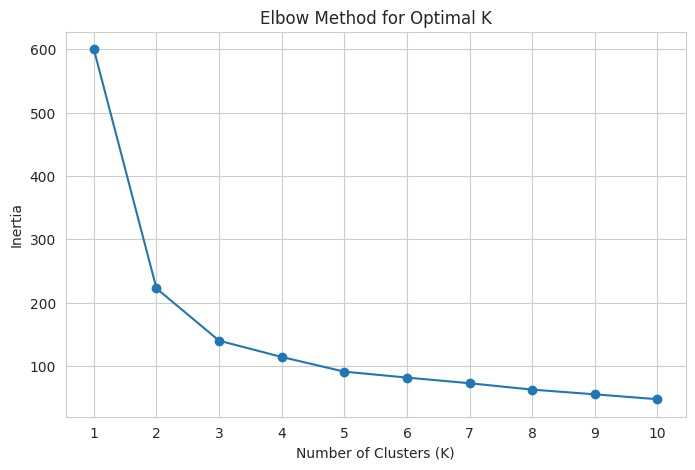

In [ ]:
# Calculate inertia for different numbers of clusters

inertia = []

K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(K_range)
plt.show()

# Apply K-Means with K=3

In [ ]:
# Create K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit model and predict clusters
kmeans_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to dataframe
df["KMeans_Cluster"] = kmeans_labels

print("Cluster labels:")
print(kmeans_labels)

Cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


# K-Means Visualization Using First Two Features

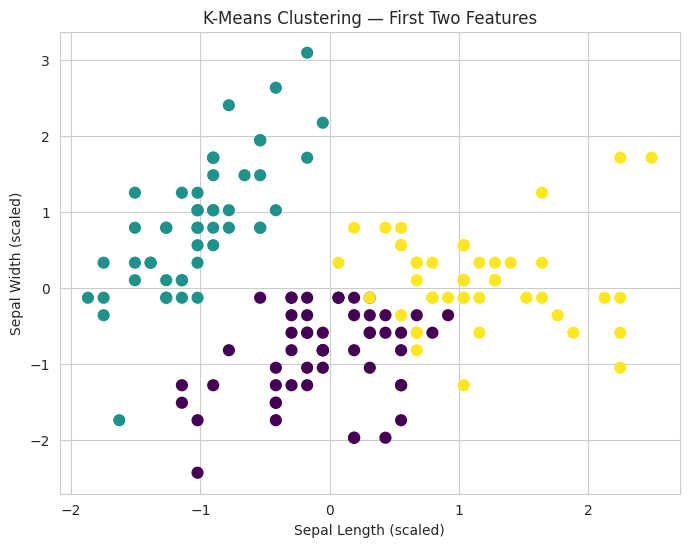

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=60
)

plt.xlabel("Sepal Length (scaled)")
plt.ylabel("Sepal Width (scaled)")
plt.title("K-Means Clustering — First Two Features")

plt.show()

# K-Means 3D Visualization

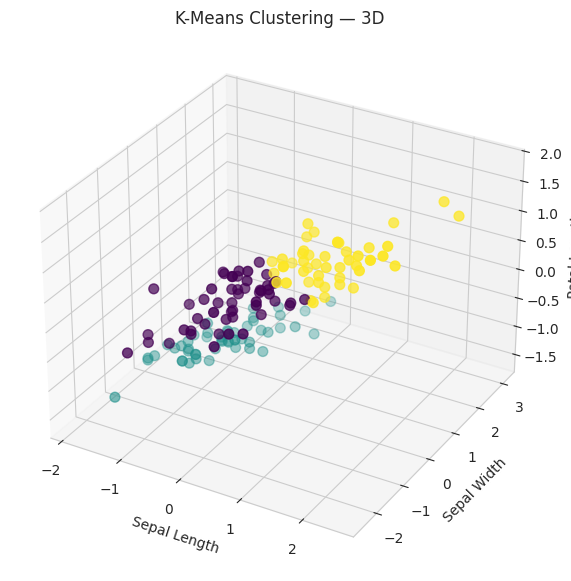

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(9, 7))

ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    X_scaled[:, 2],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)

ax.set_xlabel("Sepal Length")
ax.set_ylabel("Sepal Width")
ax.set_zlabel("Petal Length")

ax.set_title("K-Means Clustering — 3D")

plt.show()

# K-Means Silhouette Score

In [ ]:
kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)

print("K-Means Silhouette Score:",
      round(kmeans_silhouette, 4))

K-Means Silhouette Score: 0.4599


# **PCA — Principal Component Analysis**

# Apply PCA

In [ ]:
# Create PCA model with 2 components
pca = PCA(n_components=2)

# Transform standardized data
X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("PCA shape:", X_pca.shape)

Original shape: (150, 4)
PCA shape: (150, 2)


So PCA reduced the dimensionality from 4D → 2D.

# Explained Variance Ratio

In [ ]:
# Explained variance ratio
explained_variance = pca.explained_variance_ratio_

print("Explained Variance Ratio:")

for i, variance in enumerate(explained_variance, start=1):
    print(f"PC{i}: {variance:.4f}")

print(
    "\nTotal Explained Variance:",
    round(explained_variance.sum(), 4)
)

Explained Variance Ratio:
PC1: 0.7296
PC2: 0.2285

Total Explained Variance: 0.9581


# PCA Visualization

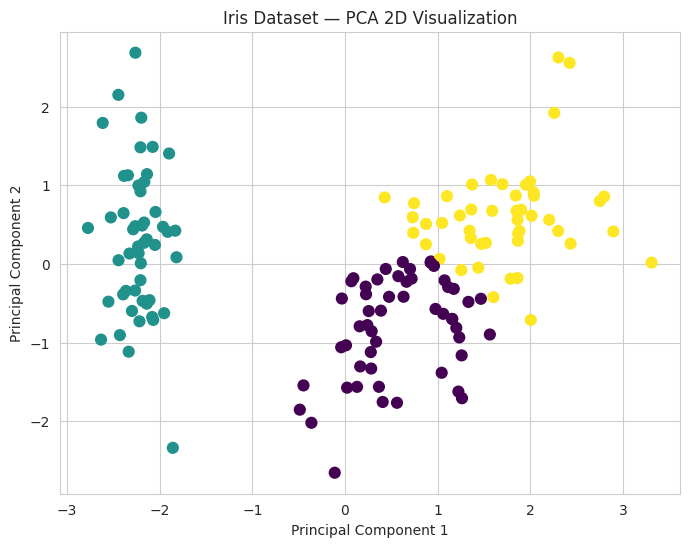

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("Iris Dataset — PCA 2D Visualization")

plt.show()

# PCA Visualization Using Actual Species

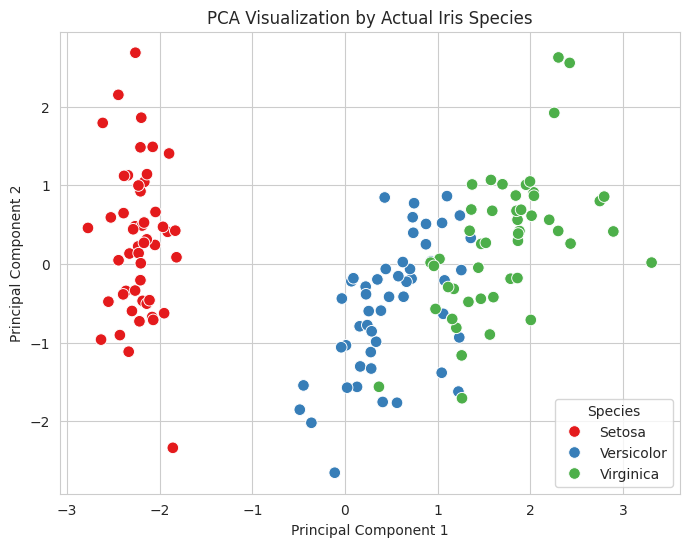

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["species"],
    palette="Set1",
    s=70
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Visualization by Actual Iris Species")

plt.legend(title="Species")

plt.show()

# K-Means on PCA-Reduced Data

In [ ]:
# K-Means on PCA-reduced data

kmeans_pca = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

pca_labels = kmeans_pca.fit_predict(X_pca)

print("PCA K-Means cluster labels:")
print(pca_labels)

PCA K-Means cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


# Compare Original vs PCA Clustering

In [ ]:
# Silhouette score on original standardized data
original_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)

# Silhouette score on PCA data
pca_silhouette = silhouette_score(
    X_pca,
    pca_labels
)

comparison = pd.DataFrame({
    "Dataset": [
        "Original 4D Data",
        "PCA 2D Data"
    ],
    "Silhouette Score": [
        original_silhouette,
        pca_silhouette
    ]
})

comparison

,Dataset,Silhouette Score
0,Original 4D Data,0.459948
1,PCA 2D Data,0.509168


PCA reduces the number of dimensions while preserving much of the important variance, so clustering can still produce meaningful groups using only two components.

# PCA vs Original Visualization

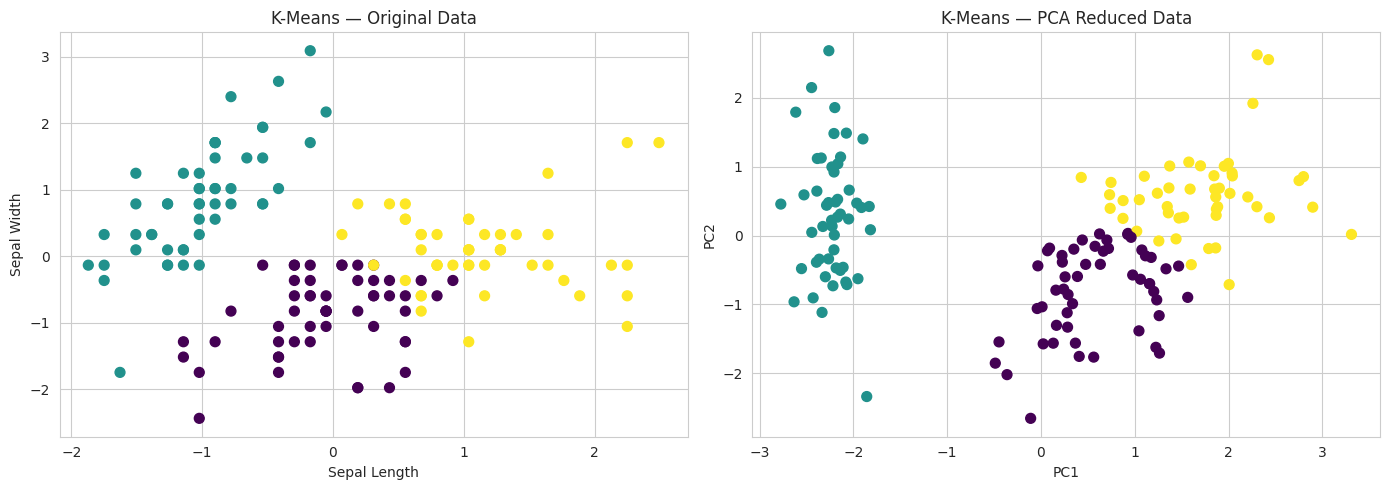

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original data
axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)

axes[0].set_title("K-Means — Original Data")
axes[0].set_xlabel("Sepal Length")
axes[0].set_ylabel("Sepal Width")

# PCA data
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pca_labels,
    cmap="viridis",
    s=50
)

axes[1].set_title("K-Means — PCA Reduced Data")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

# **Hierarchical Clustering**

# Create Linkage Matrix

In [ ]:
# Create linkage matrix
Z = linkage(
    X_scaled,
    method="ward"
)

print("Linkage matrix shape:", Z.shape)

Linkage matrix shape: (149, 4)


# Draw Dendrogram

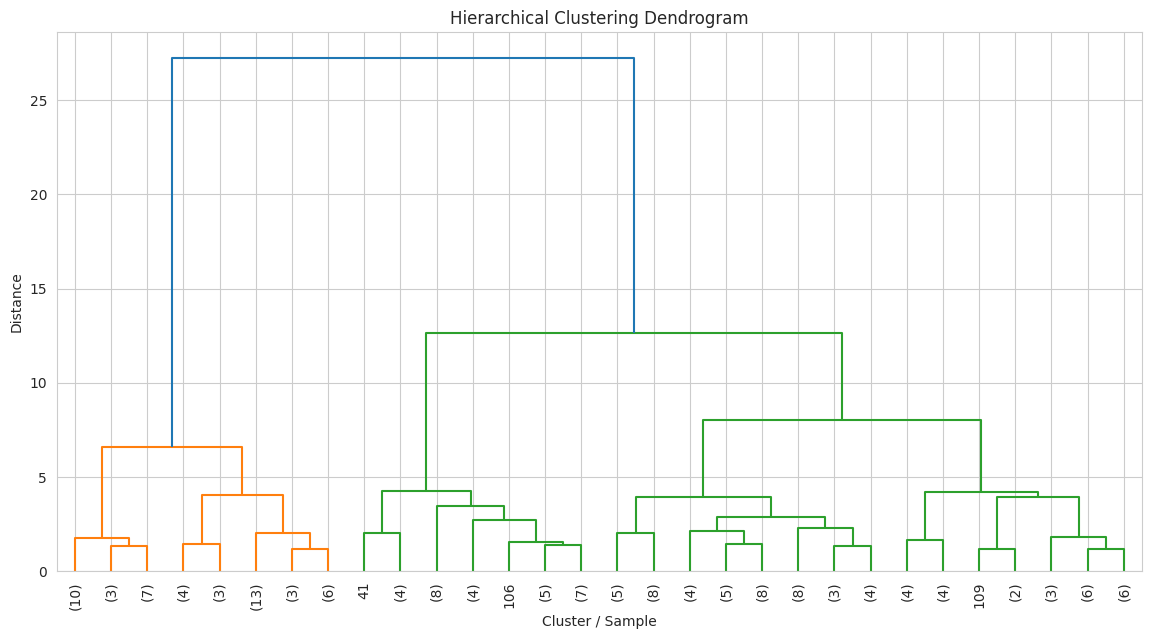

In [ ]:
plt.figure(figsize=(14, 7))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster / Sample")
plt.ylabel("Distance")

plt.show()

The dendrogram shows how observations are progressively merged into larger clusters.

The vertical distance represents the distance at which clusters are joined.

By selecting an appropriate horizontal cut, we can obtain approximately 3 clusters.

# **Apply Agglomerative Clustering**

In [ ]:
# Hierarchical / Agglomerative Clustering

hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("Hierarchical cluster labels:")
print(hierarchical_labels)

Hierarchical cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


# Visualize Hierarchical Clusters

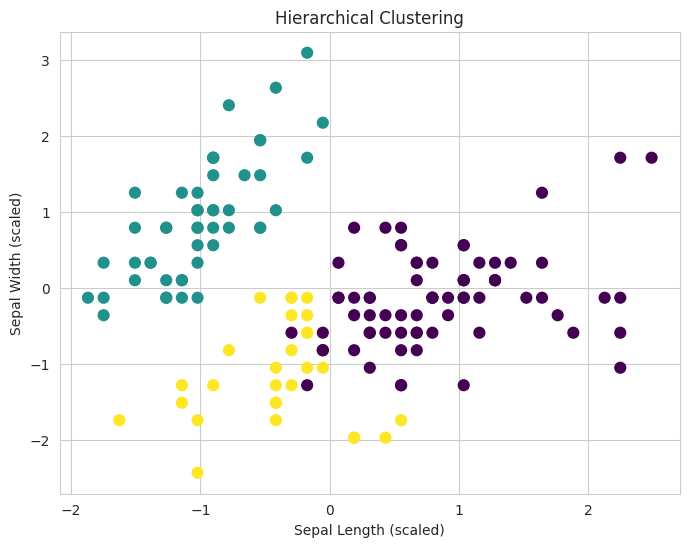

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    s=60
)

plt.xlabel("Sepal Length (scaled)")
plt.ylabel("Sepal Width (scaled)")

plt.title("Hierarchical Clustering")

plt.show()

# Compare K-Means and Hierarchical Clustering

In [ ]:
# Silhouette scores

hierarchical_silhouette = silhouette_score(
    X_scaled,
    hierarchical_labels
)

print("K-Means Silhouette Score:",
      round(kmeans_silhouette, 4))

print("Hierarchical Silhouette Score:",
      round(hierarchical_silhouette, 4))

K-Means Silhouette Score: 0.4599
Hierarchical Silhouette Score: 0.4467


Interpretation

Both methods divide the Iris dataset into three groups.

However, they use different strategies:

K-Means

1. Starts with cluster centers.
2. Assigns observations to the nearest center.
3. Recalculates centers repeatedly.

Hierarchical Clustering

1. Starts with individual observations.
2. Progressively merges similar observations/clusters.
3. Produces a dendrogram.

# **DBSCAN**

# DBSCAN with Initial Parameters

In [ ]:
# Apply DBSCAN

dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

print("DBSCAN labels:")
print(dbscan_labels)

print("\nUnique labels:")
print(np.unique(dbscan_labels))

DBSCAN labels:
[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1 -1  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0 -1 -1  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1 -1 -1  1 -1 -1  1 -1  1  1  1  1  1 -1  1  1  1
 -1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1 -1  1  1  1  1  1 -1  1  1
  1  1 -1  1 -1  1  1  1  1 -1 -1 -1 -1 -1  1  1  1  1 -1  1  1 -1 -1 -1
  1  1 -1  1  1 -1  1  1  1 -1 -1 -1  1  1  1 -1 -1  1  1  1  1  1  1  1
  1  1  1  1 -1  1]

Unique labels:
[-1  0  1]


# Count DBSCAN Clusters and Noise

In [ ]:
# Count noise points
noise_count = np.sum(dbscan_labels == -1)

# Count clusters excluding noise
n_clusters = len(
    set(dbscan_labels)
    - {-1}
)

print("Number of clusters:", n_clusters)
print("Number of noise points:", noise_count)

Number of clusters: 2
Number of noise points: 34


# Plot DBSCAN Clusters

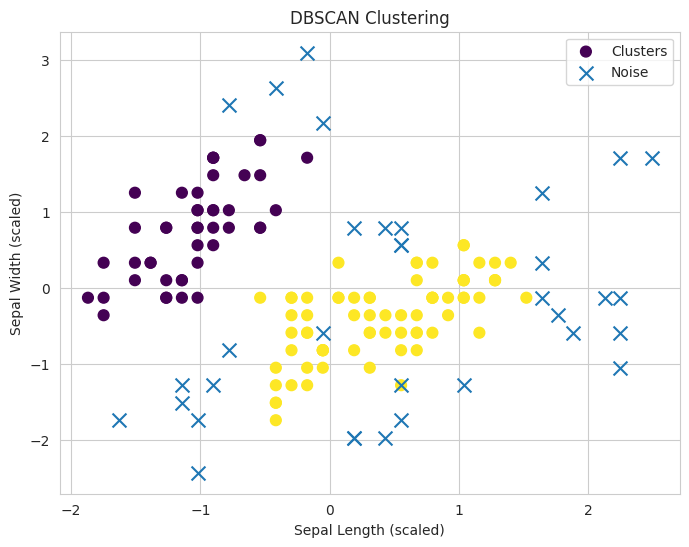

In [ ]:
plt.figure(figsize=(8, 6))

# Create mask for noise
noise = dbscan_labels == -1

# Plot normal points
plt.scatter(
    X_scaled[~noise, 0],
    X_scaled[~noise, 1],
    c=dbscan_labels[~noise],
    cmap="viridis",
    s=60,
    label="Clusters"
)

# Plot noise separately
plt.scatter(
    X_scaled[noise, 0],
    X_scaled[noise, 1],
    marker="x",
    s=100,
    label="Noise"
)

plt.xlabel("Sepal Length (scaled)")
plt.ylabel("Sepal Width (scaled)")

plt.title("DBSCAN Clustering")

plt.legend()

plt.show()

# Experiment with Different eps

In [ ]:
eps_values = [0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels) - {-1})

    n_noise = np.sum(labels == -1)

    results.append({
        "eps": eps,
        "clusters": n_clusters,
        "noise_points": n_noise
    })

dbscan_eps_results = pd.DataFrame(results)

dbscan_eps_results

,eps,clusters,noise_points
0,0.3,3,120
1,0.4,6,66
2,0.5,2,34
3,0.6,2,26
4,0.7,2,6


# Experiment with Different min_samples

In [ ]:
min_samples_values = [3, 4, 5, 6, 8, 10]

results = []

for min_samples in min_samples_values:

    model = DBSCAN(
        eps=0.5,
        min_samples=min_samples
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels) - {-1})

    n_noise = np.sum(labels == -1)

    results.append({
        "min_samples": min_samples,
        "clusters": n_clusters,
        "noise_points": n_noise
    })

dbscan_min_samples_results = pd.DataFrame(results)

dbscan_min_samples_results

,min_samples,clusters,noise_points
0,3,7,17
1,4,2,33
2,5,2,34
3,6,4,42
4,8,3,59
5,10,3,89


# Visualize Different DBSCAN Parameters

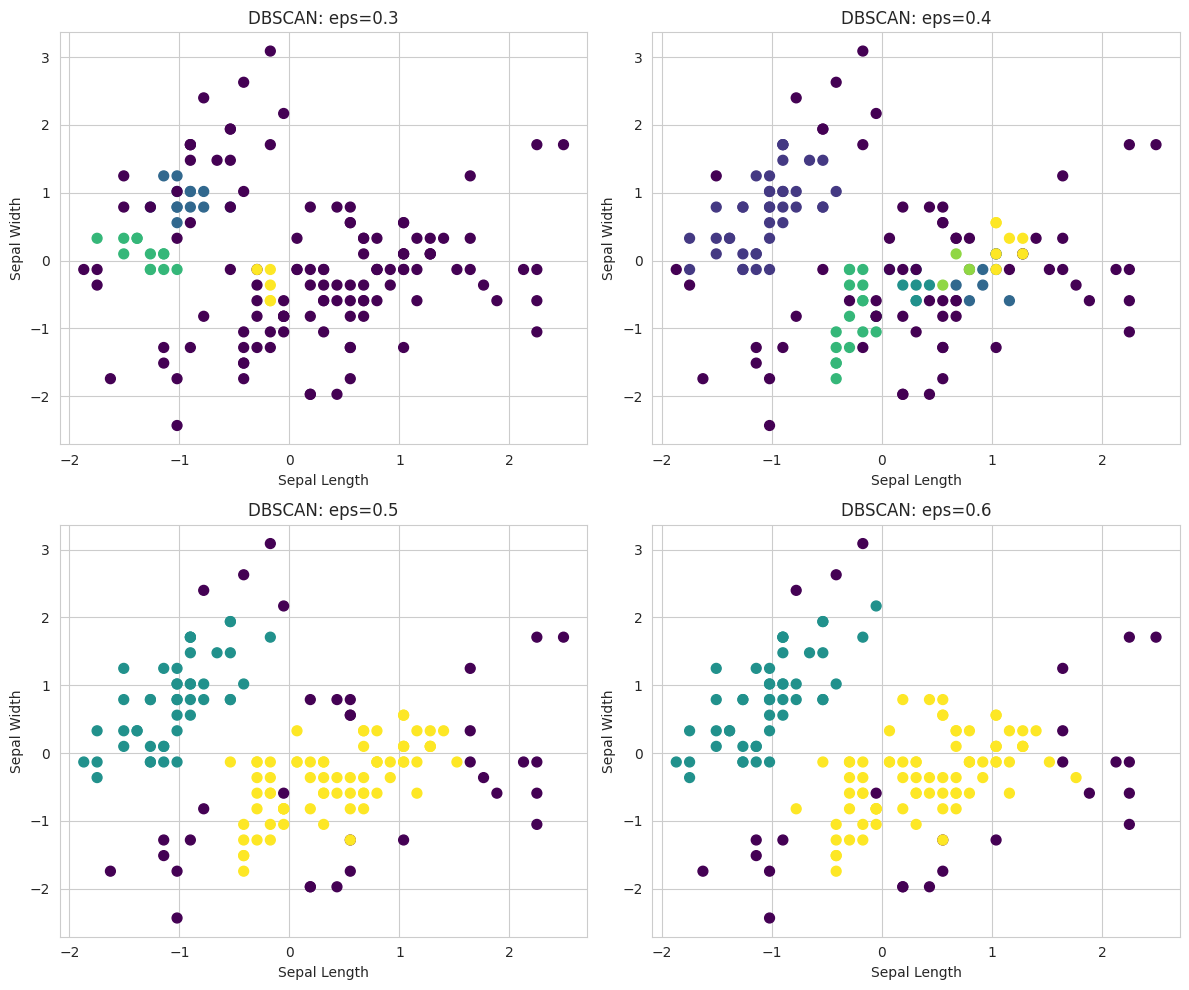

In [ ]:
eps_values = [0.3, 0.4, 0.5, 0.6]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10)
)

for ax, eps in zip(axes.ravel(), eps_values):

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled)

    ax.scatter(
        X_scaled[:, 0],
        X_scaled[:, 1],
        c=labels,
        cmap="viridis",
        s=50
    )

    ax.set_title(f"DBSCAN: eps={eps}")

    ax.set_xlabel("Sepal Length")
    ax.set_ylabel("Sepal Width")

plt.tight_layout()
plt.show()

# Compare DBSCAN with K-Means

In [ ]:
print("K-Means")
print("----------------")
print("Number of clusters:",
      len(set(kmeans_labels)))

print("\nDBSCAN")
print("----------------")
print("Number of clusters:",
      len(set(dbscan_labels) - {-1}))

print("Number of noise points:",
      np.sum(dbscan_labels == -1))

K-Means
----------------
Number of clusters: 3

DBSCAN
----------------
Number of clusters: 2
Number of noise points: 34


# Adjusted Rand Index

In [ ]:
ari_kmeans = adjusted_rand_score(
    iris.target,
    kmeans_labels
)

ari_hierarchical = adjusted_rand_score(
    iris.target,
    hierarchical_labels
)

ari_dbscan = adjusted_rand_score(
    iris.target,
    dbscan_labels
)

comparison_ari = pd.DataFrame({
    "Method": [
        "K-Means",
        "Hierarchical",
        "DBSCAN"
    ],
    "Adjusted Rand Index": [
        ari_kmeans,
        ari_hierarchical,
        ari_dbscan
    ]
})

comparison_ari

,Method,Adjusted Rand Index
0,K-Means,0.620135
1,Hierarchical,0.615323
2,DBSCAN,0.442099


# Final Comparison Table

In [ ]:
# Calculate DBSCAN silhouette only if there are
# at least 2 clusters and valid non-noise points

dbscan_clusters = set(dbscan_labels) - {-1}

if len(dbscan_clusters) >= 2:

    non_noise = dbscan_labels != -1

    dbscan_silhouette = silhouette_score(
        X_scaled[non_noise],
        dbscan_labels[non_noise]
    )

else:
    dbscan_silhouette = np.nan


final_comparison = pd.DataFrame({
    "Method": [
        "K-Means",
        "Hierarchical",
        "DBSCAN"
    ],

    "Number of Clusters": [
        len(set(kmeans_labels)),
        len(set(hierarchical_labels)),
        len(set(dbscan_labels) - {-1})
    ],

    "Silhouette Score": [
        kmeans_silhouette,
        hierarchical_silhouette,
        dbscan_silhouette
    ],

    "ARI": [
        ari_kmeans,
        ari_hierarchical,
        ari_dbscan
    ]
})

final_comparison

,Method,Number of Clusters,Silhouette Score,ARI
0,K-Means,3,0.459948,0.620135
1,Hierarchical,3,0.446689,0.615323
2,DBSCAN,2,0.655889,0.442099


# Final Visualization of All Methods

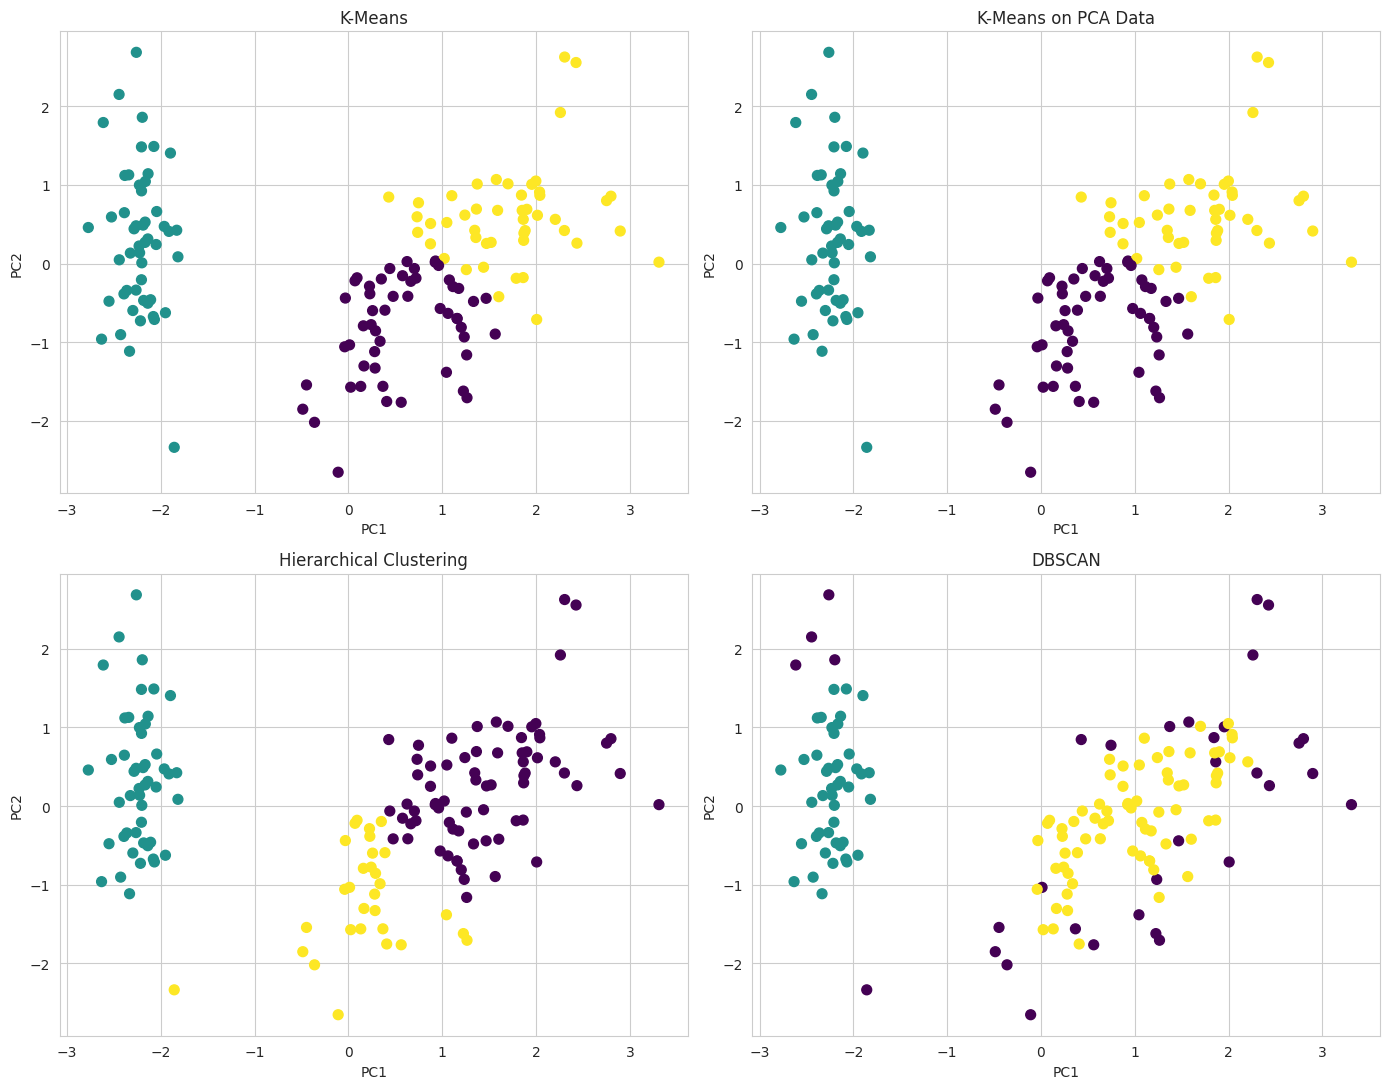

In [ ]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11)
)

# -------------------------
# K-Means
# -------------------------
axes[0, 0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=50
)

axes[0, 0].set_title("K-Means")
axes[0, 0].set_xlabel("PC1")
axes[0, 0].set_ylabel("PC2")


# -------------------------
# PCA K-Means
# -------------------------
axes[0, 1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pca_labels,
    cmap="viridis",
    s=50
)

axes[0, 1].set_title("K-Means on PCA Data")
axes[0, 1].set_xlabel("PC1")
axes[0, 1].set_ylabel("PC2")


# -------------------------
# Hierarchical
# -------------------------
axes[1, 0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="viridis",
    s=50
)

axes[1, 0].set_title("Hierarchical Clustering")
axes[1, 0].set_xlabel("PC1")
axes[1, 0].set_ylabel("PC2")


# -------------------------
# DBSCAN
# -------------------------
axes[1, 1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap="viridis",
    s=50
)

axes[1, 1].set_title("DBSCAN")
axes[1, 1].set_xlabel("PC1")
axes[1, 1].set_ylabel("PC2")


plt.tight_layout()
plt.show()

# K-Means

The Elbow Method was used to determine a suitable number of clusters. The inertia curve showed an elbow around K = 3. K-Means was therefore applied with three clusters. The resulting clusters captured the main structure of the Iris dataset.


# PCA

PCA reduced the original four-dimensional feature space to two principal components. The first two components retained a large proportion of the dataset's variance, allowing the Iris observations to be visualized effectively in two dimensions. The PCA plot showed clear separation of Setosa, while Versicolor and Virginica had some overlap.


# Hierarchical Clustering

Agglomerative hierarchical clustering with Ward linkage was applied to the standardized Iris features. The dendrogram illustrated the progressive merging of observations into larger groups. Cutting the hierarchy into three clusters produced a clustering structure broadly similar to K-Means.


# DBSCAN

DBSCAN was tested using different values of eps and min_samples. The results showed that these parameters strongly affect the number of clusters and noise points. Unlike K-Means, DBSCAN does not require the number of clusters to be specified in advance and can identify noise points.